In [1]:
import numpy as np
import json
import cv2
import matplotlib.pyplot as plt

from copy import deepcopy
from scipy.optimize import minimize
from pathlib import Path

In [2]:
# Paths
experiment_name = 'gamepad'
path_before = Path(f'../data/real/remove/single/{experiment_name}/{experiment_name}/before')
path_after = Path(f'../data/real/remove/single/{experiment_name}/{experiment_name}/after')

In [3]:
# Load transformation
with open(path_before / 'transforms.json', 'r') as file:
    transforms_before = json.load(file)

with open(path_after / 'transforms.json', 'r') as file:
    transforms_after = json.load(file)

print(len(transforms_before["frames"]), len(transforms_after["frames"]))

244 249


In [4]:
# # Sort frames
# transforms_before["frames"] = sorted(transforms_before["frames"], key=lambda x: x["file_path"])
# transforms_after["frames"] = sorted(transforms_after["frames"], key=lambda x: x["file_path"])

In [5]:
# # Calculate distance between frames
# distances_before = []
# for i in range(len(transforms_before["frames"]) - 1):
#     first = np.array(transforms_before["frames"][i]["transform_matrix"])[:3, 3]
#     second = np.array(transforms_before["frames"][i + 1]["transform_matrix"])[:3, 3]
#     distances_before.append(np.linalg.norm(second - first))

# distances_after = []
# for i in range(len(transforms_after["frames"]) - 1):
#     first = np.array(transforms_after["frames"][i]["transform_matrix"])[:3, 3]
#     second = np.array(transforms_after["frames"][i + 1]["transform_matrix"])[:3, 3]
#     distances_after.append(np.linalg.norm(second - first))

# print(len(distances_before), len(distances_after))
# print(sum(distances_before), sum(distances_after))
# print(max(distances_before), max(distances_after))
# print(min(distances_before), min(distances_after))
# print(distances_before)
# print(distances_after)

In [6]:
# # Interpolate distances
# def interpolate_distances(distances):
#     interpolated = []
#     for i in range(len(distances) - 1):
#         interpolated.append(distances[i])
#         interpolated.extend(np.linspace(distances[i], distances[i + 1], num=6, endpoint=False)[1:])
#     interpolated.append(distances[-1])
#     return interpolated

# distances_before_inerpolated = interpolate_distances(distances_before)
# distances_after_interpolated = interpolate_distances(distances_after)

# print(len(distances_before_inerpolated), len(distances_after_interpolated))
# print(distances_before_inerpolated)
# print(distances_after_interpolated)

In [7]:
# from scipy.optimize import minimize_scalar

# # Reduce number of frames
# num_frames = 250

# def optimize_dist(dist, distances):
#     selected_frames = []
#     current_distance = 0

#     for idx, distance in enumerate(distances):
#         current_distance += distance
#         if current_distance >= dist:
#             selected_frames.append(idx)
#             current_distance = 0

#     return abs(len(selected_frames) - num_frames)

# result = minimize_scalar(optimize_dist, args=(distances_before_inerpolated))
# dist_before = result.x

# # Recalculate selected_frames with optimized dist_before
# selected_frames_before = []
# current_distance = 0

# for idx, distance in enumerate(distances_before_inerpolated):
#     current_distance += distance
#     if current_distance >= dist_before:
#         selected_frames_before.append(idx)
#         current_distance = 0

# print(f"Optimized dist_before: {dist_before}")
# print(f"Selected {len(selected_frames_before)} frames out of {len(distances_before_inerpolated)}")

# result = minimize_scalar(optimize_dist, args=(distances_after_interpolated))
# dist_after = result.x

# # Recalculate selected_frames with optimized dist_after
# selected_frames_after = []
# current_distance = 0

# for idx, distance in enumerate(distances_after_interpolated):
#     current_distance += distance
#     if current_distance >= dist_after:
#         selected_frames_after.append(idx)
#         current_distance = 0

# print(f"Optimized dist_after: {dist_after}")
# print(f"Selected {len(selected_frames_after)} frames out of {len(distances_after_interpolated)}")
# print(selected_frames_before)
# print(selected_frames_after)

In [8]:
# # Selecnt new transforms
# transforms_before["frames"] = list(np.array(transforms_before["frames"])[selected_frames_before])
# transforms_after["frames"] = list(np.array(transforms_after["frames"])[selected_frames_after])

In [9]:
# Load images
images_before = []
for frame in transforms_before["frames"]:
    images_before.append(cv2.imread(str(path_before / frame["file_path"])))

images_after = []
for frame in transforms_after["frames"]:
    images_after.append(cv2.imread(str(path_after / frame["file_path"])))

In [10]:
def get_marker_pose(corners, camera_matrix, dist_coeffs):
    """ Compute the pose of a marker given its corners. """
    # Define the length of the marker's side (in meters or other units)
    marker_length = 0.1  # Adjust based on your marker size
    # Create an object point array (3D points in the marker's coordinate system)
    obj_points = np.array([
        [-marker_length / 2, marker_length / 2, 0],
        [marker_length / 2, marker_length / 2, 0],
        [marker_length / 2, -marker_length / 2, 0],
        [-marker_length / 2, -marker_length / 2, 0]
    ], dtype=np.float32)

    # Solve the PnP problem to get rotation and translation vectors
    _, rvec, tvec = cv2.solvePnP(obj_points, corners, camera_matrix, dist_coeffs, False, cv2.SOLVEPNP_IPPE_SQUARE)
    return rvec, tvec

In [11]:
# Define ArUco dictionary and parameters
dictionary = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_100)
parameters = cv2.aruco.DetectorParameters()
detector = cv2.aruco.ArucoDetector(dictionary, parameters)

In [12]:
# Define camera parameters for world before
camera_matrix = np.array([[transforms_before["fl_x"], 0, transforms_before["cx"]], 
                        [0, transforms_before["fl_y"], transforms_before["cy"]], 
                        [0, 0, 1]])
dist_coeffs = np.zeros((4, 1))

# Detect Aruco markers
arucos_before = []
for image, frame in zip(images_before, transforms_before["frames"]):
    corners, ids, _ = detector.detectMarkers(image)

    for i in range(len(corners)):
        # Compute poses
        rvec, tvec = get_marker_pose(corners[i], camera_matrix, dist_coeffs)

        R, _ = cv2.Rodrigues(rvec)
        
        trans = np.eye(4)
        trans[:3, :3] = R
        trans[:3, 3:] = tvec

        # Convert rotation vectors to matrices
        transform_matrix = np.array(frame["transform_matrix"])

        transform = np.array([[1, 0, 0, 0],
                              [0, -1, 0, 0],
                              [0, 0, -1, 0],
                              [0, 0, 0, 1]])

        marker_pose = (transform_matrix, transform @ trans, ids[i][0])
        
        arucos_before.append(marker_pose)

In [13]:
# Define camera parameters for world after
camera_matrix = np.array([[transforms_after["fl_x"], 0, transforms_after["cx"]], 
                        [0, transforms_after["fl_y"], transforms_after["cy"]], 
                        [0, 0, 1]])
dist_coeffs = np.zeros((4, 1))

# Detect Aruco markers
arucos_after = []
for image, frame in zip(images_after, transforms_after["frames"]):
    corners, ids, _ = detector.detectMarkers(image)

    for i in range(len(corners)):
        # Compute poses
        rvec, tvec = get_marker_pose(corners[i], camera_matrix, dist_coeffs)

        R, _ = cv2.Rodrigues(rvec)
        
        trans = np.eye(4)
        trans[:3, :3] = R
        trans[:3, 3:] = tvec

        # Convert rotation vectors to matrices
        transform_matrix = np.array(frame["transform_matrix"])

        transform = np.array([[1, 0, 0, 0],
                              [0, -1, 0, 0],
                              [0, 0, -1, 0],
                              [0, 0, 0, 1]])

        marker_pose = (transform_matrix, transform @ trans, ids[i][0])
        
        arucos_after.append(marker_pose)

In [14]:
# # Definition of optimization objective  
# def objective(scale):
#     aruco_dict = {}
#     for i in range(100):
#         aruco_dict[i] = []

#     for trans_mat, trans, idx in arucos:
#         temp = deepcopy(trans_mat)
#         temp[:3, 3:] = temp[:3, 3:] / scale[0]
#         aruco_dict[idx].append(temp @ trans)

#     marker_poses_0 = np.array(aruco_dict[0])
#     marker_poses_1 = np.array(aruco_dict[1])
#     marker_poses_2 = np.array(aruco_dict[2])
#     marker_poses_3 = np.array(aruco_dict[3])

#     sum_0 = np.abs(np.sum(np.diff(marker_poses_0[:, :3, 3], axis=0)))
#     sum_1 = np.abs(np.sum(np.diff(marker_poses_1[:, :3, 3], axis=0)))
#     sum_2 = np.abs(np.sum(np.diff(marker_poses_2[:, :3, 3], axis=0)))
#     sum_3 = np.abs(np.sum(np.diff(marker_poses_3[:, :3, 3], axis=0)))
    
#     return sum_0 + sum_1 + sum_2 + sum_3

In [15]:
# Definition of optimization objective  
def objective(scale, arucos = None, rand_0 = None, rand_1 = None, rand_2 = None, rand_3 = None):

    aruco_dict = {}
    for i in range(100):
        aruco_dict[i] = []

    for trans_mat, trans, idx in arucos:
        temp = deepcopy(trans_mat)
        temp[:3, 3:] = temp[:3, 3:] / scale[0]
        aruco_dict[idx].append(temp @ trans)

    marker_poses_0 = np.array(aruco_dict[0])
    marker_poses_1 = np.array(aruco_dict[1])
    marker_poses_2 = np.array(aruco_dict[2])
    marker_poses_3 = np.array(aruco_dict[3])

    sum_0 = 0
    for i in range(len(aruco_dict[0]) - 1):
        sum_0 += np.linalg.norm(marker_poses_0[rand_0[i + 1], :3, 3] - marker_poses_0[rand_0[i], :3, 3])

    sum_1 = 0
    for i in range(len(aruco_dict[1]) - 1):
        sum_1 += np.linalg.norm(marker_poses_1[rand_1[i + 1], :3, 3] - marker_poses_1[rand_1[i], :3, 3])

    sum_2 = 0
    for i in range(len(aruco_dict[2]) - 1):
        sum_2 += np.linalg.norm(marker_poses_2[rand_2[i + 1], :3, 3] - marker_poses_2[rand_2[i], :3, 3])

    sum_3 = 0
    for i in range(len(aruco_dict[3]) - 1):
        sum_3 += np.linalg.norm(marker_poses_3[rand_3[i + 1], :3, 3] - marker_poses_3[rand_3[i], :3, 3])

    side_0 = np.linalg.norm(np.mean(marker_poses_0[:, :3, 3], axis=0) - np.mean(marker_poses_1[:, :3, 3], axis=0)) - 0.6
    side_1 = np.linalg.norm(np.mean(marker_poses_1[:, :3, 3], axis=0) - np.mean(marker_poses_3[:, :3, 3], axis=0)) - 0.6
    side_2 = np.linalg.norm(np.mean(marker_poses_2[:, :3, 3], axis=0) - np.mean(marker_poses_3[:, :3, 3], axis=0)) - 0.6
    side_3 = np.linalg.norm(np.mean(marker_poses_2[:, :3, 3], axis=0) - np.mean(marker_poses_0[:, :3, 3], axis=0)) - 0.6
    diag_1 = np.linalg.norm(np.mean(marker_poses_0[:, :3, 3], axis=0) - np.mean(marker_poses_3[:, :3, 3], axis=0)) - np.hypot(0.6, 0.6)
    diag_2 = np.linalg.norm(np.mean(marker_poses_1[:, :3, 3], axis=0) - np.mean(marker_poses_2[:, :3, 3], axis=0)) - np.hypot(0.6, 0.6)
    
    print(f"Mean distance: {side_0:.2f}, {side_1:.2f}, {side_2:.2f}, {side_3:.2f}, {diag_1:.2f}, {diag_2:.2f}, Sum distance: {sum_0:.2f}, {sum_1:.2f}, {sum_2:.2f}, {sum_3:.2f}")
    
    return sum_0 + sum_1 + sum_2 + sum_3 + 100 * (side_0 + side_1 + side_2 + side_3 + diag_1 + diag_2)

In [16]:
# Optimize for best scale
scale_min, scale_max = 0, 20
rand_start = scale_min + np.random.rand(1) * (scale_max - scale_min)
n_nieghbours = 50

aruco_dict = {}
for i in range(100):
    aruco_dict[i] = []

for trans_mat, trans, idx in arucos_before:
    aruco_dict[idx].append(idx)

rand_0 = np.random.randint(0, len(aruco_dict[0]), size=(len(aruco_dict[0]), n_nieghbours))
rand_1 = np.random.randint(0, len(aruco_dict[1]), size=(len(aruco_dict[1]), n_nieghbours))
rand_2 = np.random.randint(0, len(aruco_dict[2]), size=(len(aruco_dict[2]), n_nieghbours))
rand_3 = np.random.randint(0, len(aruco_dict[3]), size=(len(aruco_dict[3]), n_nieghbours))

result = minimize(objective, rand_start, method='nelder-mead', options={'maxiter': 1000}, args=(arucos_before, rand_0, rand_1, rand_2, rand_3))
print(result)
best_scale_before = result['x']

aruco_dict = {}
for i in range(100):
    aruco_dict[i] = []

for trans_mat, trans, idx in arucos_after:
    aruco_dict[idx].append(idx)

rand_0 = np.random.randint(0, len(aruco_dict[0]), size=(len(aruco_dict[0]), n_nieghbours))
rand_1 = np.random.randint(0, len(aruco_dict[1]), size=(len(aruco_dict[1]), n_nieghbours))
rand_2 = np.random.randint(0, len(aruco_dict[2]), size=(len(aruco_dict[2]), n_nieghbours))
rand_3 = np.random.randint(0, len(aruco_dict[3]), size=(len(aruco_dict[3]), n_nieghbours))


arucos = arucos_after
result = minimize(objective, rand_start, method='nelder-mead', options={'maxiter': 1000}, args=(arucos_after, rand_0, rand_1, rand_2, rand_3))
print(result)
best_scale_after = result['x']

Mean distance: -0.03, -0.14, 0.05, -0.11, -0.19, 0.03, Sum distance: 770.42, 707.93, 404.90, 227.80
Mean distance: -0.03, -0.14, 0.05, -0.11, -0.19, 0.03, Sum distance: 773.17, 710.45, 406.36, 228.61
Mean distance: -0.03, -0.14, 0.05, -0.11, -0.19, 0.03, Sum distance: 767.39, 705.15, 403.29, 226.90
Mean distance: -0.03, -0.14, 0.05, -0.11, -0.19, 0.03, Sum distance: 764.01, 702.05, 401.51, 225.91
Mean distance: -0.03, -0.14, 0.05, -0.11, -0.19, 0.03, Sum distance: 756.00, 694.71, 397.26, 223.55
Mean distance: -0.03, -0.14, 0.05, -0.10, -0.19, 0.03, Sum distance: 745.69, 685.26, 391.81, 220.52
Mean distance: -0.03, -0.13, 0.05, -0.10, -0.18, 0.02, Sum distance: 712.73, 655.03, 374.35, 210.81
Mean distance: -0.03, -0.12, 0.04, -0.10, -0.16, 0.02, Sum distance: 635.81, 584.52, 333.62, 188.17
Mean distance: -0.03, -0.22, 0.12, -0.13, -0.30, 0.10, Sum distance: 1405.47, 1290.09, 741.06, 414.73
Mean distance: -0.03, -0.13, 0.05, -0.10, -0.18, 0.02, Sum distance: 712.73, 655.03, 374.35, 210.8

In [17]:
def reject_outliers_iqr(points, multiplier=1.5):
    """
    Rejects outliers based on the IQR (Interquartile Range) method using NumPy.
    
    Parameters:
    - points: numpy array of shape (n_points, 3) representing 3D points
    - multiplier: the factor to multiply the IQR by to define the outlier range (default is 1.5)
    
    Returns:
    - filtered_points: numpy array with outliers removed
    """
    # Compute the 1st (Q1) and 3rd (Q3) quartiles for each dimension (x, y, z)
    Q1 = np.percentile(points, 25, axis=0)
    Q3 = np.percentile(points, 75, axis=0)
    
    # Compute the Interquartile Range (IQR)
    IQR = Q3 - Q1
    
    # Calculate lower and upper bounds for each dimension
    lower_bound = Q1 - multiplier * IQR
    upper_bound = Q3 + multiplier * IQR
    
    # Find the points that lie within the bounds for each dimension
    mask = np.all((points >= lower_bound) & (points <= upper_bound), axis=1)
    
    # Return the filtered points (outliers removed)
    return points[mask, :]

In [18]:
# Apply best scale and create aruco dictionary
aruco_dict_before = {}
for i in range(100):
    aruco_dict_before[i] = []

camera_path_before = []
i = 0

aruco_t = []
# world_to_aruco_t = []

# Calculate mean of aruco positions
for aruco_id in range(4):
    aruco_ts = []
    world_to_aruco_ts = []
    for trans_mat, trans, idx in arucos_before:
        temp = deepcopy(trans_mat)
        temp[:3, 3:] = temp[:3, 3:] / best_scale_before
        marker_pose = temp @ trans
        if idx == aruco_id:
            # R = deepcopy(marker_pose[:3, :3])
            aruco_ts.append(deepcopy(marker_pose[:3, 3:]))
            # marker_pose[:3, 3:] = R.T @ marker_pose[:3, 3:]
            # world_to_aruco_ts.append(deepcopy(marker_pose[:3, 3:]))

    # world_to_aruco_ts = np.array(world_to_aruco_ts)
    # world_to_aruco_ts = reject_outliers_iqr(world_to_aruco_ts[:, :, 0])
    # world_to_aruco_t.append(np.mean(world_to_aruco_ts, axis=0))

    aruco_ts = np.array(aruco_ts)
    aruco_ts = reject_outliers_iqr(aruco_ts[:, :, 0])
    aruco_t.append(np.mean(aruco_ts, axis=0))

    # plt.figure()
    # plt.hist(np.array(world_to_aruco_ts)[:, 0])
    # plt.hist(np.array(world_to_aruco_ts)[:, 1])
    # plt.hist(np.array(world_to_aruco_ts)[:, 2])
    # plt.show()

# print(world_to_aruco_t)

0.004012688587072238
-0.6836395704240263
0.9953044796609409
[-2.74049539e-03  5.77624954e-01 -7.13490757e-21]
[ 5.75001595e-01  1.32476138e-20 -1.19915282e-18]
[[ 9.99777950e-01  1.73696310e-02  1.19308946e-02]
 [-1.73692301e-02  9.99849134e-01 -1.37231283e-04]
 [-1.19314783e-02 -7.00296424e-05  9.99928815e-01]]


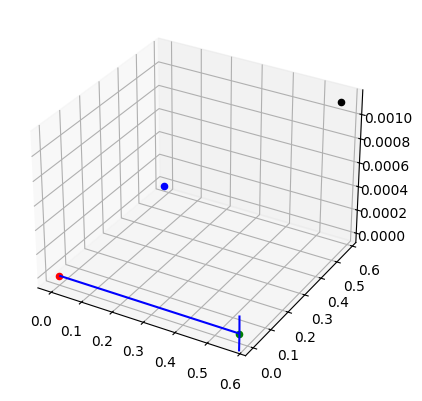

In [19]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

points = np.array(aruco_t)

aruco_0 = points[0] - points[0]
aruco_1 = points[1] - points[0]
aruco_2 = points[2] - points[0]
aruco_3 = points[3] - points[0]

gamma = np.arctan2(-aruco_1[1], aruco_1[0])

Rz = np.array([[np.cos(gamma), -np.sin(gamma), 0],
               [np.sin(gamma), np.cos(gamma), 0],
               [0, 0, 1]])

aruco_1 = Rz @ aruco_1
aruco_2 = Rz @ aruco_2
aruco_3 = Rz @ aruco_3

beta = np.arctan2(aruco_1[2], aruco_1[0])
Ry = np.array([[np.cos(beta), 0, np.sin(beta)],
               [0, 1, 0],
               [-np.sin(beta), 0, np.cos(beta)]])

aruco_1 = Ry @ aruco_1
aruco_2 = Ry @ aruco_2
aruco_3 = Ry @ aruco_3

alpha = np.arctan2(-aruco_2[2], aruco_2[1])
Rx = np.array([[1, 0, 0],
               [0, np.cos(alpha), -np.sin(alpha)],
               [0, np.sin(alpha), np.cos(alpha)]])

aruco_1 = Rx @ aruco_1
aruco_2 = Rx @ aruco_2
aruco_3 = Rx @ aruco_3

print(np.rad2deg(alpha))
print(np.rad2deg(beta))
print(np.rad2deg(gamma))

world_to_aruco_R = (Rx @ Ry @ Rz).T

# aruco_1 = world_to_aruco_R @ aruco_1
# aruco_2 = world_to_aruco_R @ aruco_2
# aruco_3 = world_to_aruco_R @ aruco_3

print(aruco_2)
print(aruco_1)

ax.scatter(aruco_0[0], aruco_0[1], aruco_0[2], c='r')
ax.scatter(aruco_1[0], aruco_1[1], aruco_1[2], c='g')
ax.scatter(aruco_2[0], aruco_2[1], aruco_2[2], c='b')
ax.scatter(aruco_3[0], aruco_3[1], aruco_3[2], c='k')
ax.quiver(aruco_0[0], aruco_0[1], aruco_0[2], aruco_1[0] - aruco_0[0], aruco_1[1] - aruco_0[1], aruco_1[2] - aruco_0[2], colors='b', arrow_length_ratio=0.001)

# ax.set_xlim3d(-0.1, 1.0)
# ax.set_ylim3d(-0.1, 1.0)
# ax.set_zlim3d(-0.1, 0.1)

print(world_to_aruco_R)

plt.autoscale(False)
plt.show()

In [20]:
camera_path_before = []

# world_to_aruco_t = world_to_aruco_t[0][..., None]

world_to_aruco_t = None

# Calculate mean of aruco positions after rotation
world_to_aruco_ts = []
for trans_mat, trans, idx in arucos_before:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_before
    marker_pose = temp @ trans
    if idx == 0:
        marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
        world_to_aruco_ts.append(deepcopy(marker_pose[:3, 3:]))

world_to_aruco_ts = np.array(world_to_aruco_ts)
world_to_aruco_ts = reject_outliers_iqr(world_to_aruco_ts[:, :, 0])
world_to_aruco_t = np.mean(world_to_aruco_ts, axis=0)[..., None]

print(world_to_aruco_t)

for trans_mat, trans, idx in arucos_before:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_before
    marker_pose = temp @ trans

    marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
    marker_pose[:3, 3:] = marker_pose[:3, 3:] - world_to_aruco_t

    aruco_dict_before[idx].append(marker_pose)

    if idx == 0:
        temp[:3, 3:] = (world_to_aruco_R.T @ temp[:3, 3:]) - world_to_aruco_t
        camera_path_before.append(temp)

    i += 1

# Convert transform.json file to meters
for frame in transforms_before["frames"]:
    transform_matrix = np.array(frame["transform_matrix"])
    # Move frames from camera space to aruco id 0 space
    transform_matrix[:3, :3] = world_to_aruco_R.T @ transform_matrix[:3, :3]
    transform_matrix[:3, 3:] = transform_matrix[:3, 3:] / best_scale_before
    transform_matrix[:3, 3:] = (world_to_aruco_R.T @ transform_matrix[:3, 3:]) - world_to_aruco_t
    frame["transform_matrix"] = transform_matrix.tolist()

# with open(path_before / 'transforms.json', 'w') as file:
#     json.dump(transforms_before, file, indent=4)

[[0.00112832]
 [0.0051542 ]
 [0.00354794]]


In [21]:
# Apply best scale and create aruco dictionary
aruco_dict_after = {}
for i in range(100):
    aruco_dict_after[i] = []

camera_path_after = []
i = 0

world_to_aruco_R = None
world_to_aruco_t = None

# Setup pose of 0 aruco marker as world center
for trans_mat, trans, idx in arucos_after:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_after
    marker_pose = temp @ trans
    if idx == 0:
        world_to_aruco_R = deepcopy(marker_pose[:3, :3])
        marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
        world_to_aruco_t = deepcopy(marker_pose[:3, 3:])
        break

for trans_mat, trans, idx in arucos_after:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_after
    marker_pose = temp @ trans
    marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
    marker_pose[:3, 3:] = marker_pose[:3, 3:] - world_to_aruco_t
    aruco_dict_after[idx].append(marker_pose)

    if idx == 0:
        temp[:3, 3:] = (world_to_aruco_R.T @ temp[:3, 3:]) - world_to_aruco_t
        camera_path_after.append(temp)

    i += 1

# Convert transform.json file to meters
for frame in transforms_after["frames"]:
    transform_matrix = np.array(frame["transform_matrix"])
    transform_matrix[:3, :3] = world_to_aruco_R.T @ transform_matrix[:3, :3]
    transform_matrix[:3, 3:] = transform_matrix[:3, 3:] / best_scale_after
    transform_matrix[:3, 3:] = (world_to_aruco_R.T @ transform_matrix[:3, 3:]) - world_to_aruco_t
    frame["transform_matrix"] = transform_matrix.tolist()

# with open(path_after / 'transforms.json', 'w') as file:
#     json.dump(transforms_after, file, indent=4)

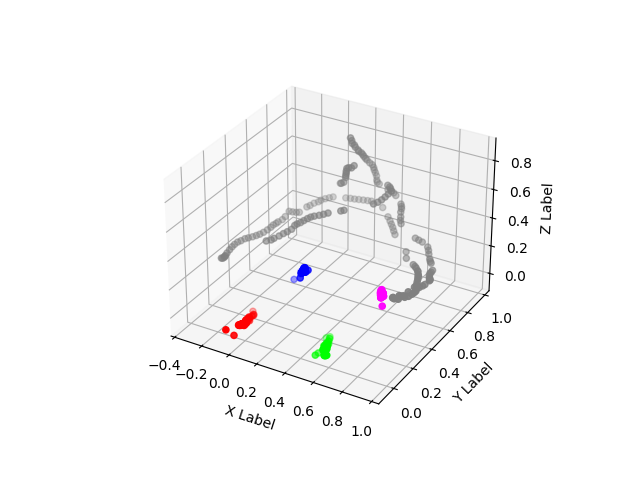

In [22]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

marker_poses_0 = np.array(aruco_dict_before[0])
marker_poses_1 = np.array(aruco_dict_before[1])
marker_poses_2 = np.array(aruco_dict_before[2])
marker_poses_3 = np.array(aruco_dict_before[3])
camera_path = np.array(camera_path_before)

start = 0
num = -1

ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_0[start:num, 2, 3]))])
ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_1[start:num, 2, 3]))])
ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(0, 0, 1, 1) for i in range(len(marker_poses_2[start:num, 2, 3]))])
ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(1, 0, 1, 1) for i in range(len(marker_poses_3[start:num, 2, 3]))])
ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 1) for i in range(len(camera_path))])

marker_poses_0 = np.array(aruco_dict_after[0])
marker_poses_1 = np.array(aruco_dict_after[1])
marker_poses_2 = np.array(aruco_dict_after[2])
marker_poses_3 = np.array(aruco_dict_after[3])
camera_path = np.array(camera_path_after)

# start = 0
# num = -1

# ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(1, 0, 0, 0.5) for i in range(len(marker_poses_0[start:num, 2, 3]))])
# ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(0, 1, 0, 0.5) for i in range(len(marker_poses_1[start:num, 2, 3]))])
# ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(0, 0, 1, 0.5) for i in range(len(marker_poses_2[start:num, 2, 3]))])
# ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(1, 0, 1, 0.5) for i in range(len(marker_poses_3[start:num, 2, 3]))])
# ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 0.5) for i in range(len(camera_path))])

# print(np.sum(np.diff(marker_poses_2[:, :3, 3], axis=0), axis=0))

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
# ax.set_zlim(-1, 1)

plt.autoscale(False)
plt.show()

[0.00423542 0.00085367 0.00149198]


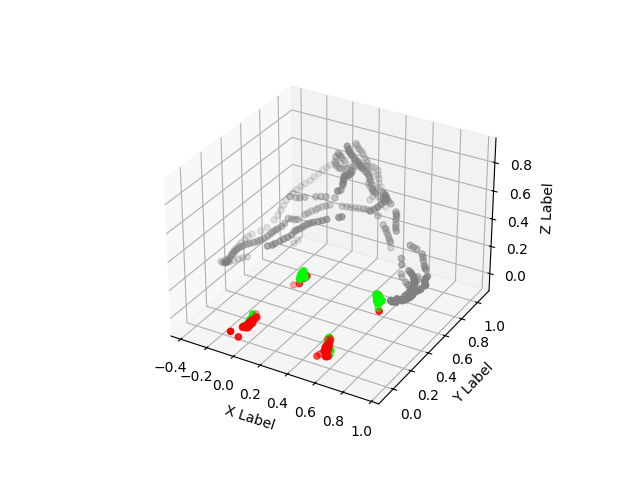

In [23]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

marker_poses_0 = np.array(aruco_dict_before[0])
marker_poses_1 = np.array(aruco_dict_before[1])
marker_poses_2 = np.array(aruco_dict_before[2])
marker_poses_3 = np.array(aruco_dict_before[3])
camera_path = np.array(camera_path_before)

start = 0
num = -1

ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_0[start:num, 2, 3]))])
ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_1[start:num, 2, 3]))])
ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_2[start:num, 2, 3]))])
ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_3[start:num, 2, 3]))])
ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 1) for i in range(len(camera_path))])

marker_poses_0 = np.array(aruco_dict_after[0])
marker_poses_1 = np.array(aruco_dict_after[1])
marker_poses_2 = np.array(aruco_dict_after[2])
marker_poses_3 = np.array(aruco_dict_after[3])
camera_path = np.array(camera_path_after)

start = 0
num = -1

ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_0[start:num, 2, 3]))])
ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_1[start:num, 2, 3]))])
ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_2[start:num, 2, 3]))])
ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_3[start:num, 2, 3]))])
ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 0.5) for i in range(len(camera_path))])

print(np.sum(np.diff(marker_poses_2[:, :3, 3], axis=0), axis=0))

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
# ax.set_zlim(-1, 1)

plt.autoscale(False)
plt.show()